<a href="https://colab.research.google.com/github/nandini17404/DATASCIENCE/blob/main/Predicting_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import sklearn
print(sklearn.__version__)

1.9.0


In [3]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df = df.drop("ocean_proximity", axis=1)

In [5]:
class Housing:
    pass

housing = Housing()

housing.data = df.drop("median_house_value", axis=1)
housing.target = df["median_house_value"]
housing.feature_names = list(housing.data.columns)

In [6]:
print(housing.feature_names)


['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


In [7]:
print(housing.target)


0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20640, dtype: float64


**PREPARE THE DATA**

In [8]:
df = pd.DataFrame(housing.data, columns= housing.feature_names)

In [9]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462


In [10]:
df['Price']=housing.target

In [11]:
df = df.dropna()

In [12]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,Price
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   Price               20433 non-null  float64
dtypes: float64(9)
memory usage: 1.6 MB


**EDA**

In [14]:
df.corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,Price
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355
Price,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000


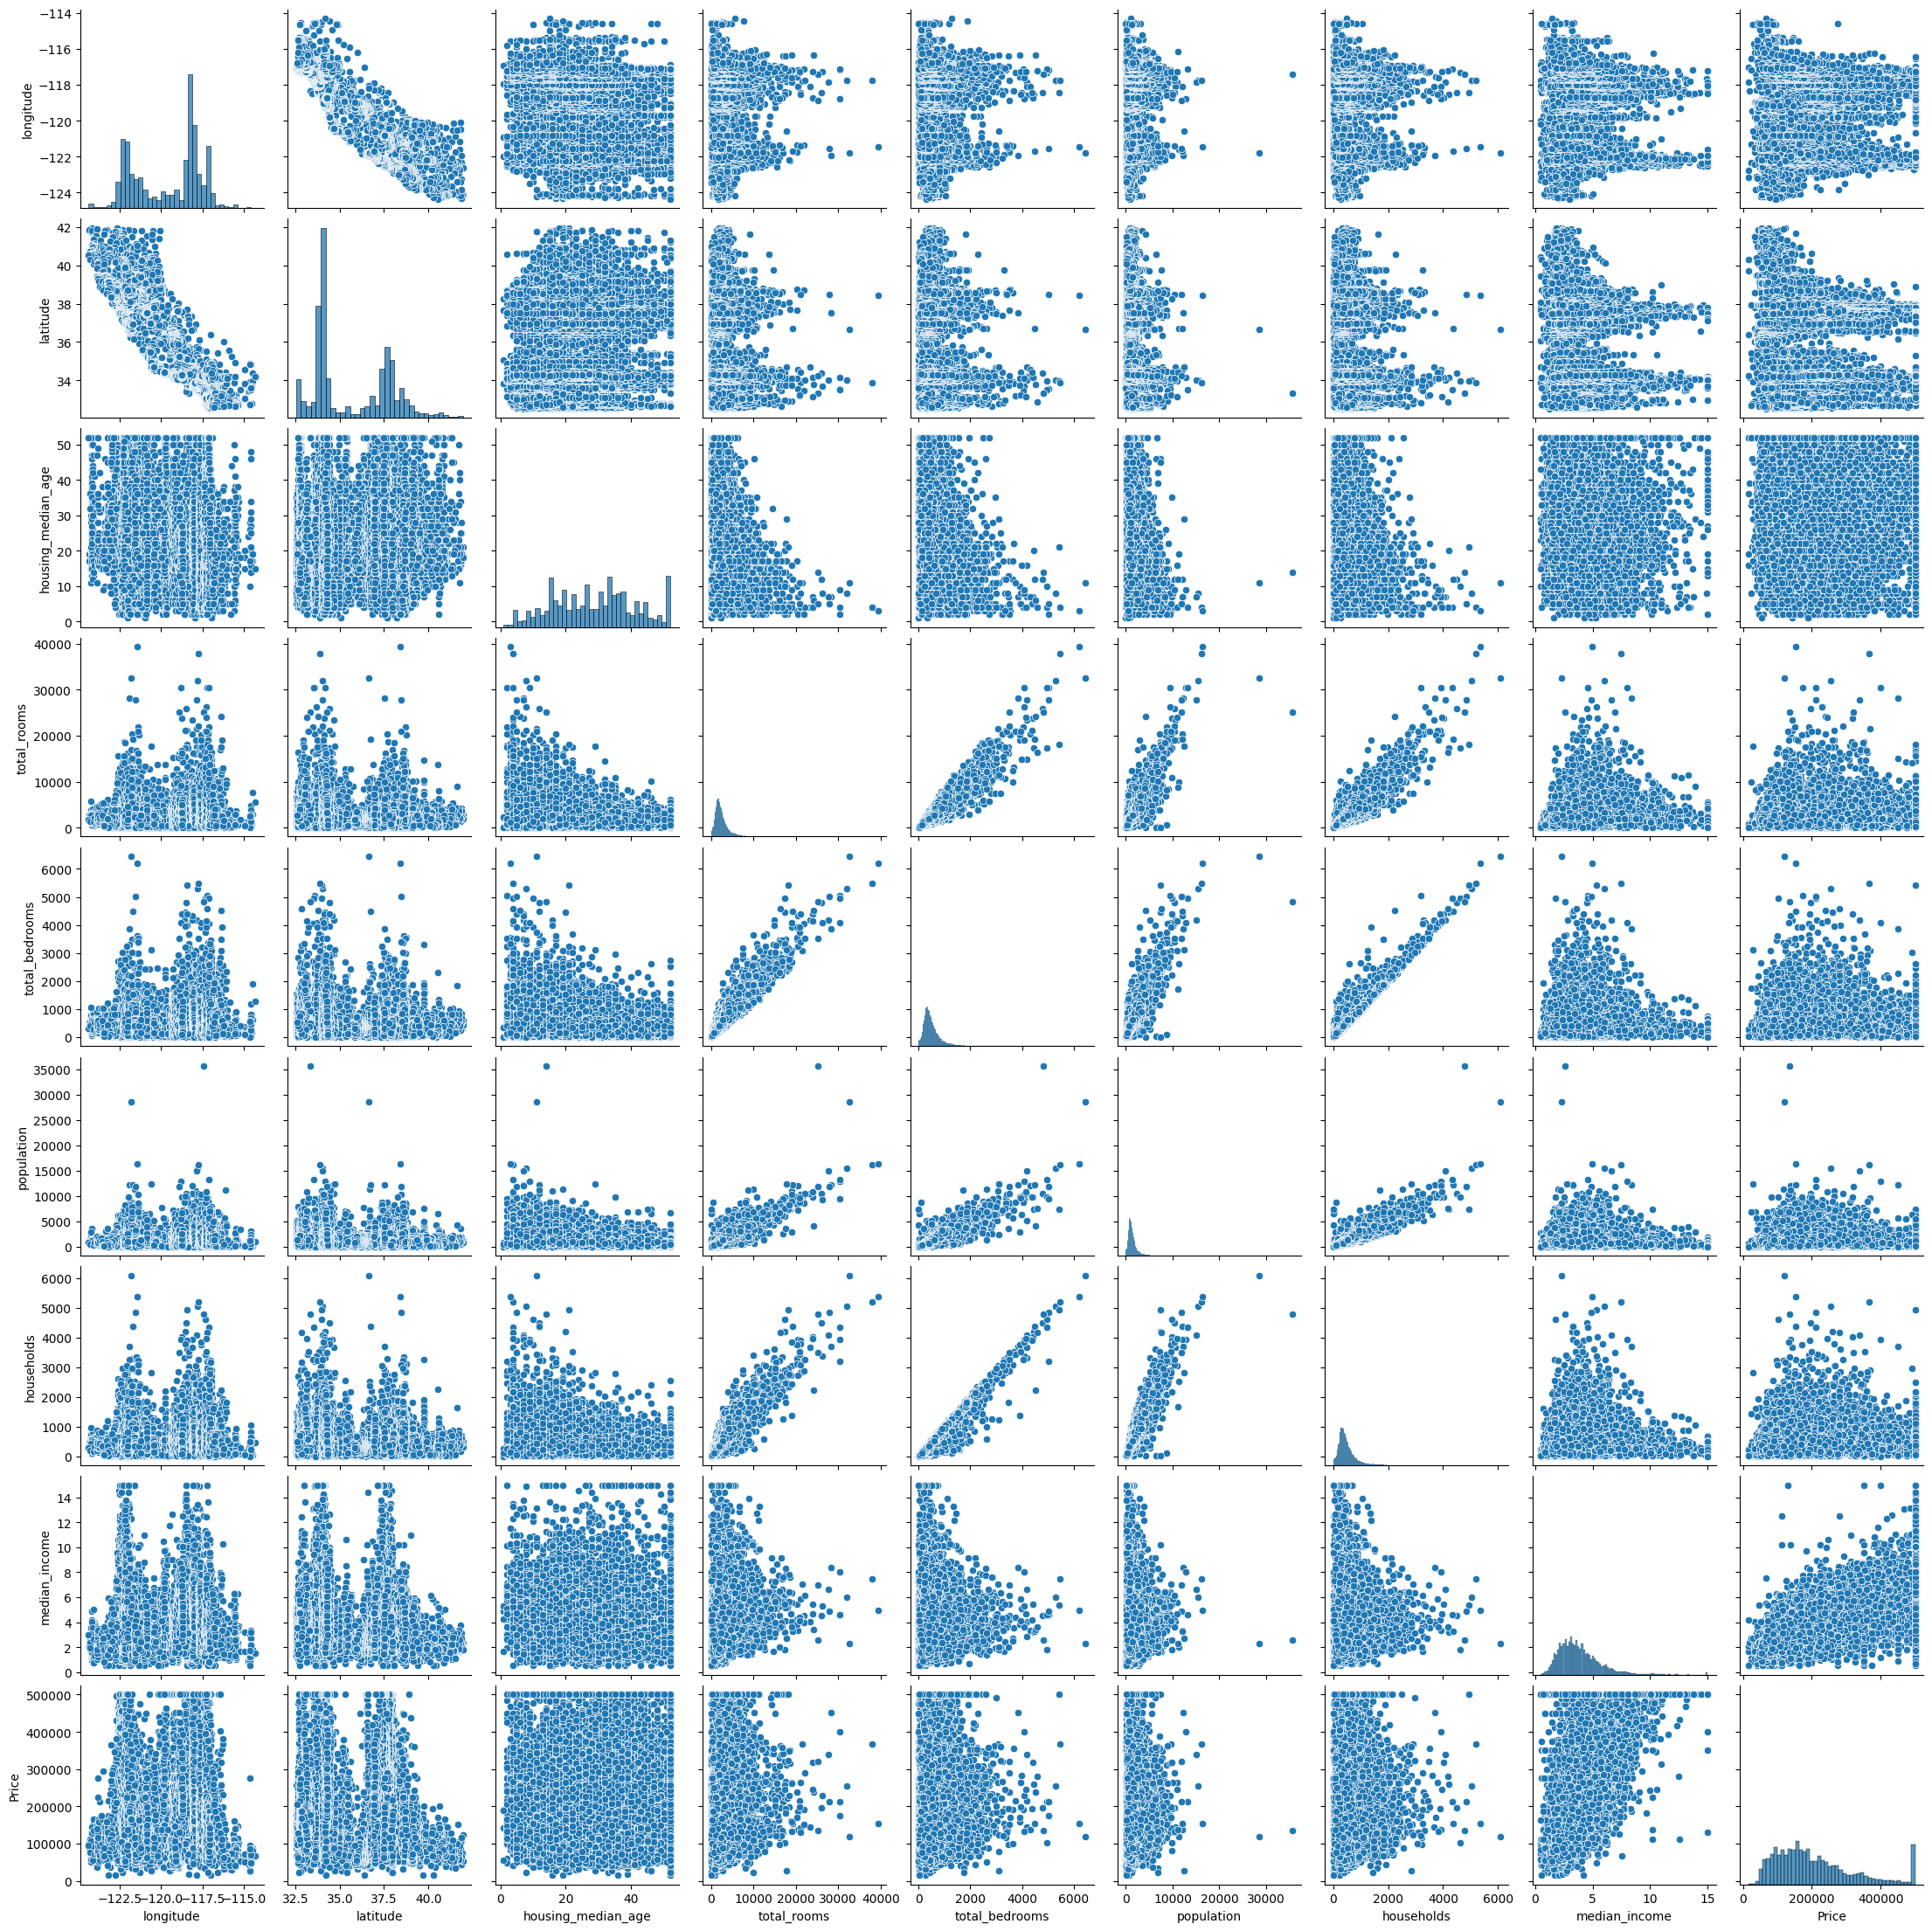

In [15]:
sns.pairplot(df)

**BoxPlot : To detect outliers in a given dataset**

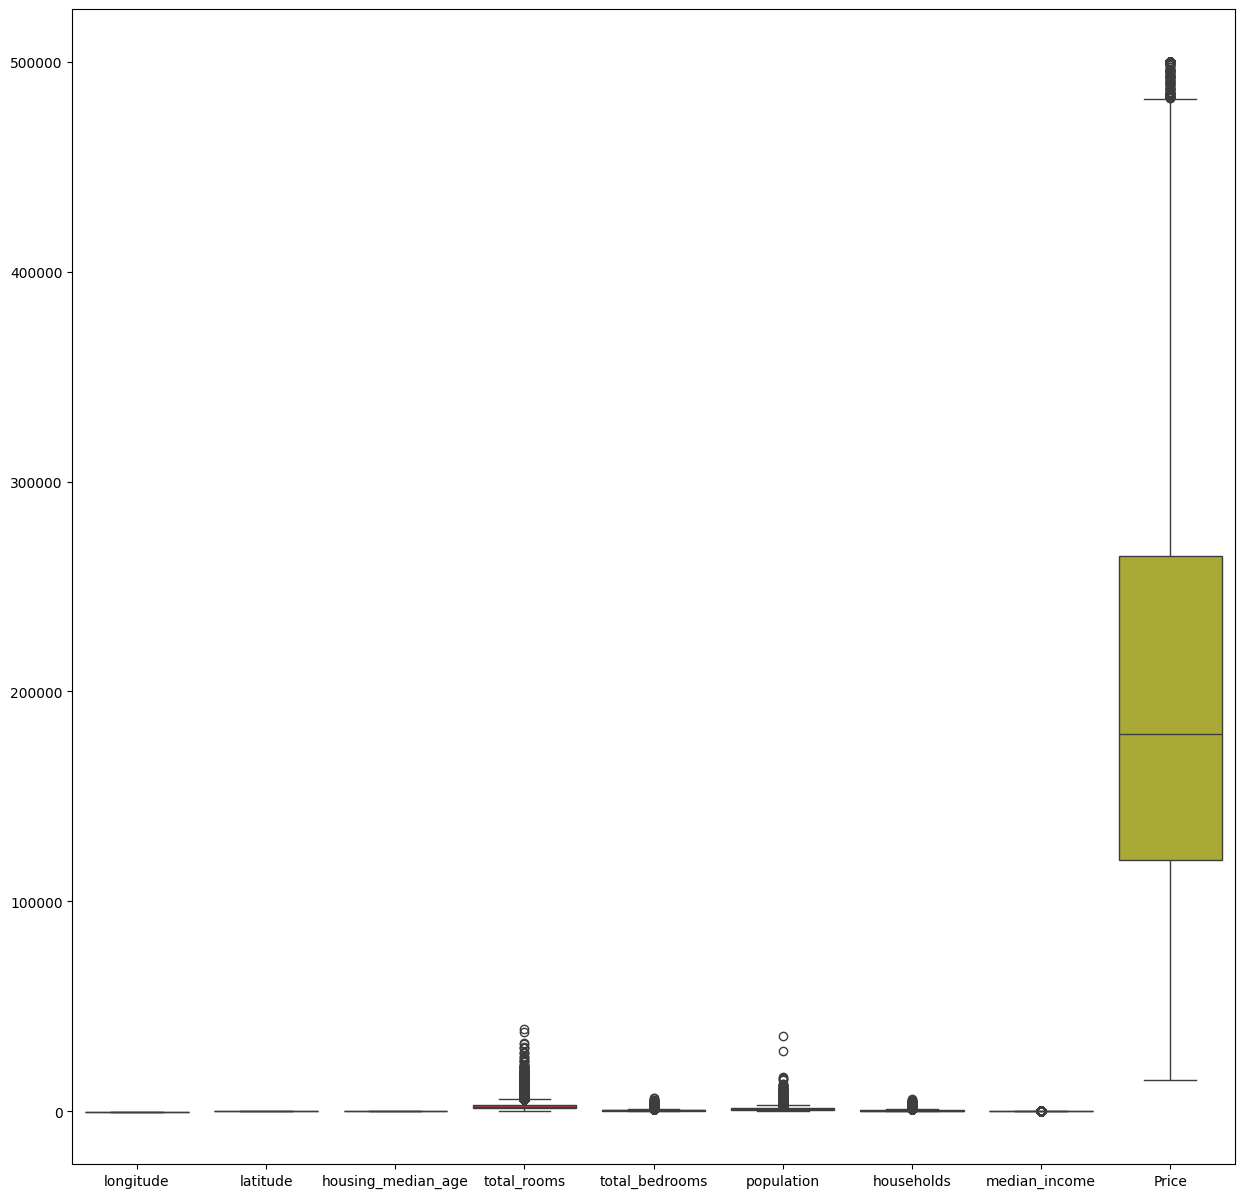

In [16]:
fig, ax = plt.subplots(figsize=(15,15))
sns.boxplot(data=df, ax=ax)
plt.savefig("boxPlot.jpg")

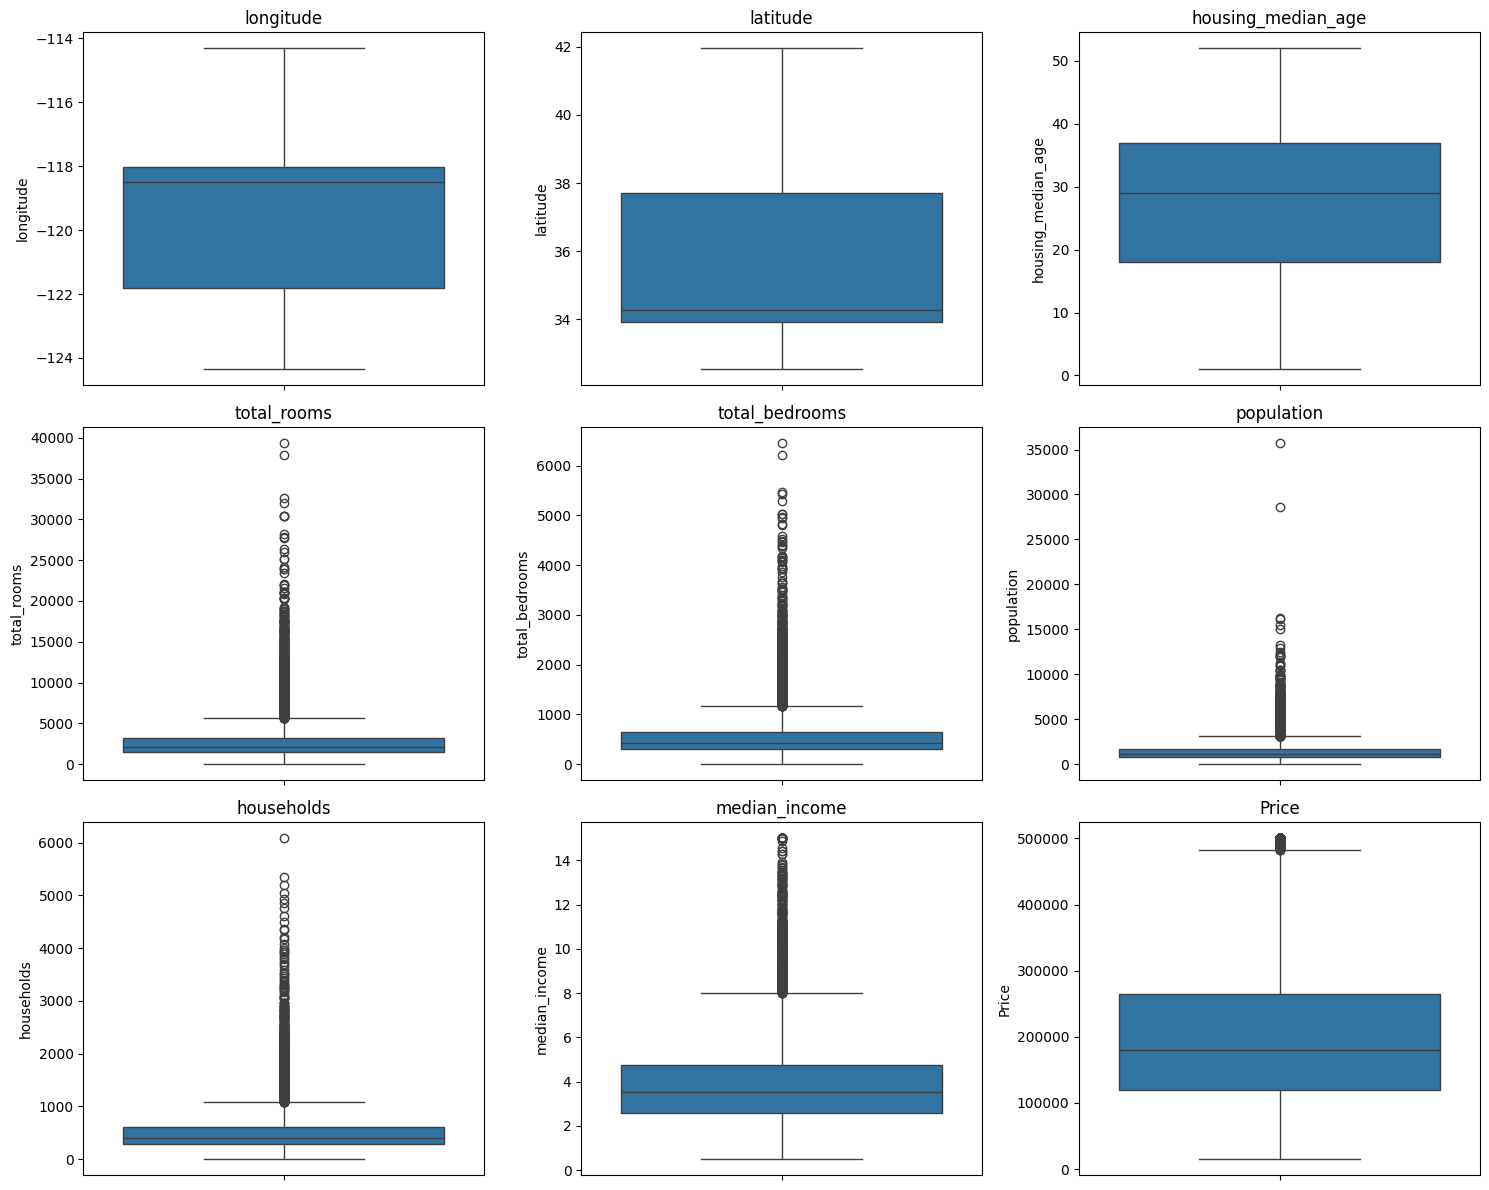

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), df.columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**SPLIT DEPENDENT & INDEPENDENT FEATURES**

In [18]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [19]:
x

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462
...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672


In [20]:
y

,Price
0,452600.0
1,358500.0
2,352100.0
3,341300.0
4,342200.0
...,...
20635,78100.0
20636,77100.0
20637,92300.0
20638,84700.0


**SPLIT DATA INTO TRIN AND TEST **

In [21]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train , y_test= train_test_split(x,y, test_size = 0.3, random_state=42)

In [22]:
x_train

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
19566,-120.96,37.61,23.0,3497.0,887.0,2467.0,816.0,1.9444
7292,-118.22,33.98,34.0,2225.0,753.0,2980.0,736.0,1.6685
17618,-121.94,37.28,27.0,2859.0,464.0,1144.0,430.0,5.0822
17518,-121.91,37.34,35.0,2189.0,607.0,1193.0,562.0,2.8042
5172,-118.28,33.95,41.0,835.0,208.0,707.0,192.0,1.4103
...,...,...,...,...,...,...,...,...
11397,-117.97,33.72,24.0,2991.0,500.0,1437.0,453.0,5.4286
12081,-117.54,33.76,5.0,5846.0,1035.0,3258.0,1001.0,4.7965
5447,-118.42,34.01,42.0,1594.0,369.0,952.0,362.0,3.0990
866,-122.04,37.57,12.0,5719.0,1064.0,3436.0,1057.0,5.2879


In [23]:
x_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14416,-117.24,32.79,20.0,961.0,278.0,525.0,254.0,3.1838
16383,-121.29,38.01,2.0,6403.0,1116.0,3327.0,957.0,4.4871
7731,-118.14,33.92,31.0,3731.0,853.0,2313.0,801.0,3.2237
1410,-122.07,37.94,30.0,1260.0,276.0,707.0,221.0,2.8920
1335,-121.89,37.99,4.0,2171.0,597.0,928.0,461.0,4.1016
...,...,...,...,...,...,...,...,...
16764,-122.49,37.70,36.0,1946.0,340.0,828.0,313.0,5.2811
5762,-118.29,34.16,31.0,1262.0,338.0,1019.0,332.0,3.7083
12862,-121.39,38.69,30.0,2897.0,506.0,1508.0,478.0,3.8650
18814,-121.45,41.04,33.0,2029.0,378.0,936.0,343.0,2.6700


**NORMALIZATION OF THE GIVEN DATA POINTS**

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_norm = scaler.fit_transform(x_train)

In [25]:
x_train_norm

array([[-0.68684567,  0.92079826, -0.44520313, ...,  0.91053523,
         0.83541917, -1.0159178 ],
       [ 0.68114892, -0.77889909,  0.42830842, ...,  1.35816955,
         0.6252194 , -1.16085401],
       [-1.1761284 ,  0.76628032, -0.12756257, ..., -0.2438901 ,
        -0.17879472,  0.63243606],
       ...,
       [ 0.5812953 , -0.76485201,  1.06358955, ..., -0.41142575,
        -0.35746453, -0.40938158],
       [-1.22605521,  0.90206881, -1.31871469, ...,  1.75606672,
         1.46864598,  0.7404947 ],
       [-1.42076977,  0.9769866 ,  1.85769097, ...,  0.73863668,
         0.39137215,  0.00793384]])

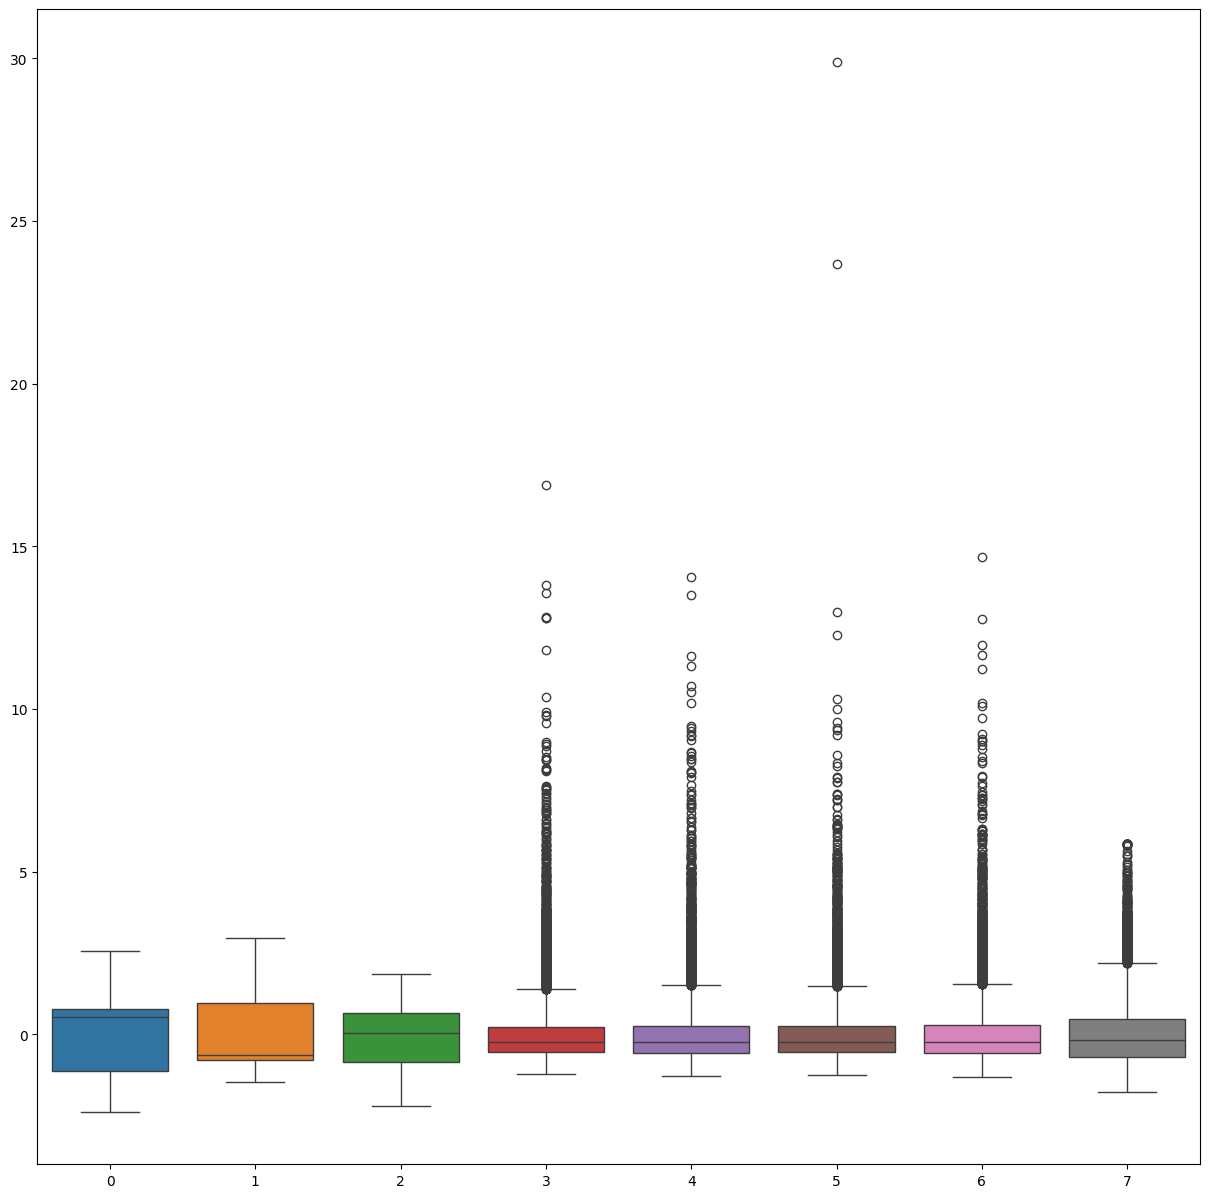

In [26]:
fig, ax = plt.subplots(figsize=(15,15))
sns.boxplot(data=x_train_norm, ax=ax)
plt.savefig("boxPlotTrainData.jpg")

In [27]:
x_test_norm = scaler.transform(x_test)

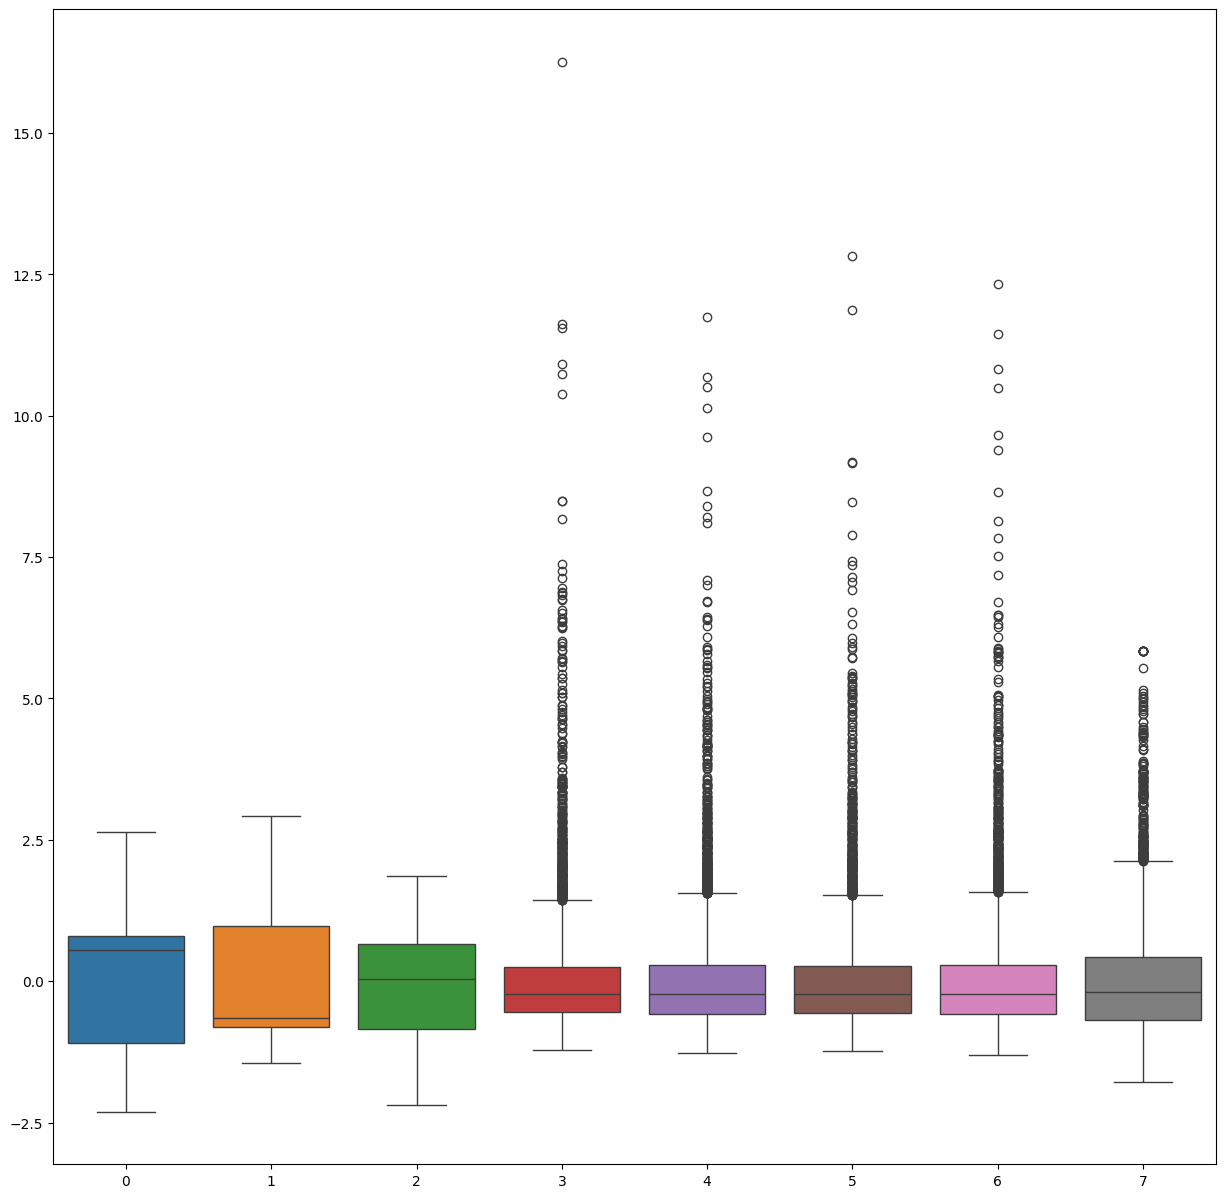

In [28]:
fig, ax = plt.subplots(figsize=(15,15))
sns.boxplot(data=x_test_norm, ax=ax)
plt.savefig("boxPlotTestData.jpg")

**MODEL TRAINING**

In [29]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()
regression.fit(x_train_norm, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-84375.97,-89831.54, 14958.42,...,-40770.03, 14221.78, 76771.51]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.073e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[236.02,165.17,123.98,..., 34.28, 26.14, 14.8 ]"


In [30]:
print(regression.coef_)

[-84375.97162725 -89831.53727522  14958.41670461 -18626.46943218
  49648.87984197 -40770.03141072  14221.77563676  76771.50828879]


In [31]:
print(regression.intercept_)

207283.98035377174


**MODEL PREDICTION**

In [32]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
Price,0


In [33]:
print(df.isnull().sum())
print(np.isnan(x_test_norm).sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
Price                 0
dtype: int64
0


In [34]:
from sklearn.impute import SimpleImputer

# Impute NaN values in x_test_norm before prediction
imputer = SimpleImputer(strategy='mean')
x_test_norm_imputed = imputer.fit_transform(x_test_norm)

reg_pred = regression.predict(x_test_norm_imputed)
reg_pred

array([196980.02029312, 158095.83507498, 203028.20805884, ...,
       146710.62625887,  13392.0574117 ,  95881.80878573])

In [35]:
# Calculate the error or the residual
residuals= y_test - reg_pred
residuals

,Price
14416,48819.979707
16383,-20195.835075
7731,15171.791941
1410,47370.342231
1335,-42351.066972
...,...
16764,-17804.604331
5762,34247.855849
12862,-58310.626259
18814,64107.942588


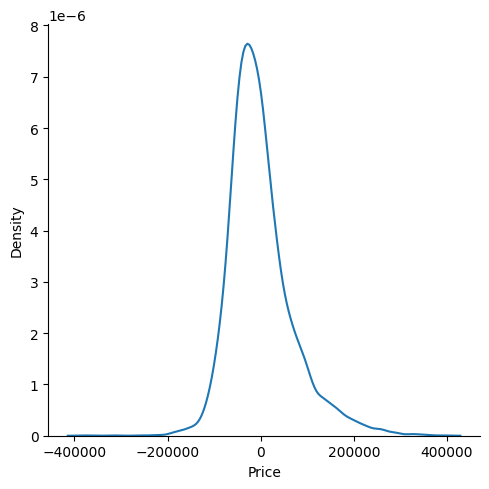

In [36]:
 sns.displot(residuals, kind='kde')

**MODEL EVALUATION**

In [37]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
print(mean_squared_error(y_test, reg_pred))
print(mean_absolute_error(y_test, reg_pred))
print(r2_score(y_test, reg_pred))

4738972791.400469
50704.919692848016
0.6445130291082353


In [39]:
score = (r2_score(y_test, reg_pred))

Adjusted R-Square

In [40]:
1-(1-score)*(len(y_test)-1)/(len(y_test)-x_test_norm.shape[1]-1)

0.6440484161745423

In [41]:
x_test_norm.shape[1]

8

Save the Model -> Pickle File




In [42]:
import pickle
pickle.dump(regression, open('model.pkl','wb'))

In [43]:
model = pickle.load(open('model.pkl','rb'))

In [50]:
housing.data.iloc[0]

,0
longitude,-122.2300
latitude,37.8800
housing_median_age,41.0000
total_rooms,880.0000
total_bedrooms,129.0000
population,322.0000
households,126.0000
median_income,8.3252


In [52]:
model.predict(scaler.transform(housing.data.iloc[0].values.reshape(1,-1)))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([410921.70290962])